In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"

In [3]:
movie = tifffile.imread(path)[:, ::2, ::2]

# Convert the data type to float32
movie = movie.astype(np.float32)

In [4]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [5]:
# n_pixels = X.shape[0]
# n_time_steps = X.shape[1]

# P = np.zeros((n_pixels,int(n_time_steps/2)))
# F = np.zeros((n_pixels,int(n_time_steps/2)))
# for col in range(0,int(n_time_steps/2)):
#     P[:,col] = X[:,2*col]
#     F[:,col] = X[:,2*col+1]

In [6]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

P = np.zeros((n_pixels,n_time_steps-1))
F = np.zeros((n_pixels,n_time_steps-1))
for col in range(0,n_time_steps-1):
    P[:,col] = X[:,col]
    F[:,col] = X[:,col+1]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
print (f"F.shape = {F.shape}")

X.shape = (1200, 2000)
P.shape = (1200, 1999)
F.shape = (1200, 1999)


In [7]:
def centered_matrix(X):
    # we assume X has a shape (n,T)
    # n = number of features
    # T = number of samples
    
    X_mean = X.mean(axis=1, keepdims=True)
    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

In [8]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [9]:
def covariance_matrix(X):
    # we assume X has a shape (n,T)
    # n = number of features
    # T = number of samples

    n = X.shape[0]
    COV = X @ X.T / float(n)
    
    return COV

In [10]:
def whitened_matrix(X):
    # we assume X has a shape (n,T)
    # n = number of features
    # T = number of samples

    COV = covariance_matrix(X)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix
    W = U @ inv_sqrt_S @ U.T

    # whitened data
    Xw = W @ X

    return Xw
    

In [11]:
def normalization_matrix(P, F):
    
    PPT = P @ P.T
    FFT = F @ F.T
    Sp, Up = eigen_decomposition(PPT)
    Sf, Uf = eigen_decomposition(FFT)

    epsilon = 1e-5
    inv_Sp = np.diag(1.0 / (Sp + epsilon))
    inv_Sf = np.diag(1.0 / (Sf + epsilon))
    
    inv_PPT = Up @ inv_Sp @ Up.T
    inv_FFT = Uf @ inv_Sf @ Uf.T

    B = linalg.block_diag(PPT, FFT)
    inv_B = linalg.block_diag(inv_PPT, inv_FFT)

    return B, inv_B

In [12]:
Pc = centered_matrix(P)
Fc = centered_matrix(F)
Pw = whitened_matrix(Pc)
Fw = whitened_matrix(Fc)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw)
print (COV)

X_mean.shape = (1200, 1)
X_mean.shape = (1200, 1)
eigenvectors.shape = (1200, 1200)
eigenvectors.shape = (1200, 1200)
P.shape = (1200, 1999)
Pw.shape = (1200, 1999)
[[ 1.00000000e+00  7.17312210e-11  2.04348168e-12 ...  1.87925956e-11
   4.97428043e-12 -5.99152283e-12]
 [ 7.17312210e-11  1.00000000e+00  5.42655935e-11 ... -2.69898282e-11
   3.10923435e-11 -4.09730620e-12]
 [ 2.04348168e-12  5.42655935e-11  1.00000000e+00 ...  4.73456681e-12
  -1.94143486e-11  1.12955515e-11]
 ...
 [ 1.87925956e-11 -2.69898282e-11  4.73456681e-12 ...  9.99999999e-01
   9.75843154e-11  2.98433345e-11]
 [ 4.97428043e-12  3.10923435e-11 -1.94143486e-11 ...  9.75843154e-11
   1.00000000e+00  1.08993652e-10]
 [-5.99152283e-12 -4.09730620e-12  1.12955515e-11 ...  2.98433345e-11
   1.08993652e-10  1.00000000e+00]]


In [13]:
# Z = np.vstack((P, F)) # orignal
# Z = np.vstack((Pc, Fc)) # centered
Z = np.vstack((Pw, Fw)) # whitened

Cpp = Pw @ Pw.T
Cff = Fw @ Fw.T

# B, inv_B = normalization_matrix(Pc, Fc)

ZTZ = Z.T @ Z
# ZTZ = Z.T @ inv_B @ Z
print (f"ZTZ.shape = {ZTZ.shape}")

ZTZ.shape = (1999, 1999)


In [14]:
S, U = eigen_decomposition(ZTZ)

eigenvectors.shape = (1999, 1999)


U.shape = (1999, 1999)


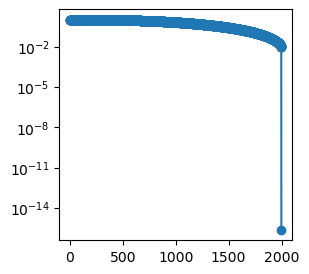

In [15]:
print (f"U.shape = {U.shape}")

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(S[:] / S.max(),'o-')
ax.set_yscale('log')
# ax.set_xscale('log')
plt.show()

In [26]:
k = 20
Uk = U[:,:k]
Sk = np.diag(np.sqrt(S[:k]))
print (f"Uk.shape = {Uk.shape}")

Uk.shape = (1999, 20)


In [27]:
fig = fpl.Figure()

fig[0, 0].add_line_stack(Uk.T, separation=0.01)

fig.show(maintain_aspect=False)

AttributeError: module 'fastplotlib' has no attribute 'Figure'

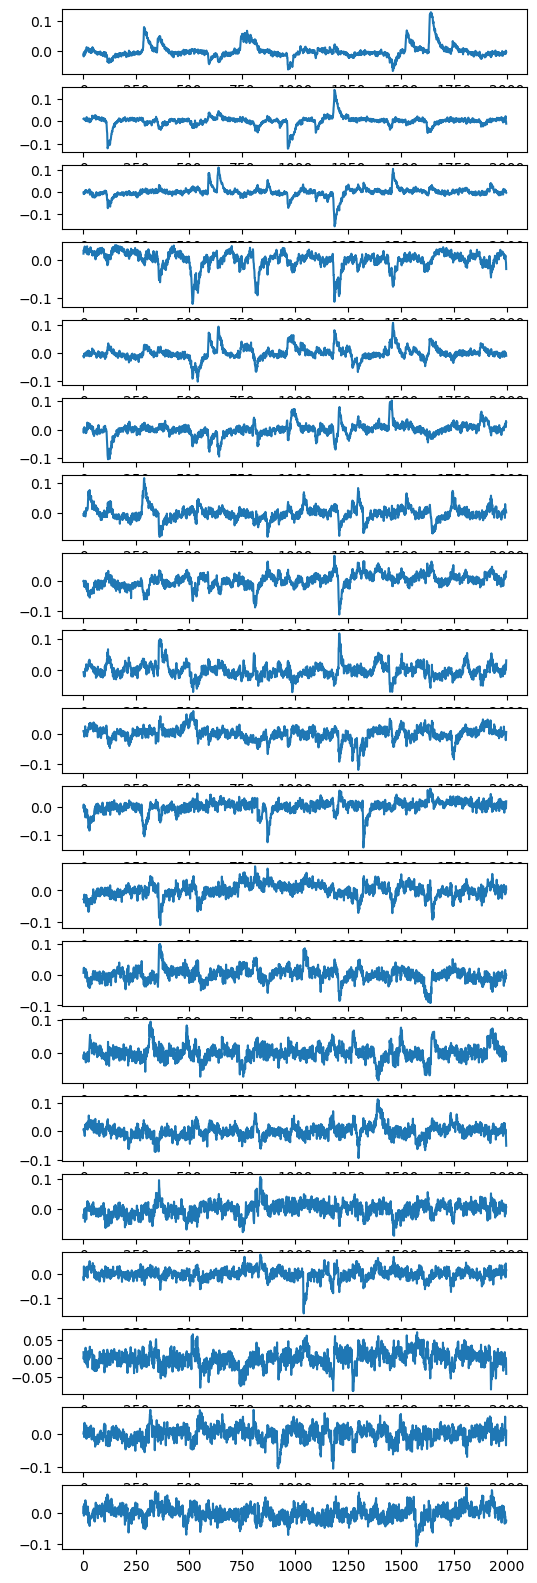

In [28]:
fig, ax = plt.subplots(k, 1, figsize=(1 * 6, k * 1))
for col in range(0,k):
    ax[col].plot(Uk[:,col].T)
plt.show()

In [29]:
from tqdm.notebook import tqdm

eta = 1e-2
error_stop = 1e-4
error_log = np.zeros(20_000)

# T = float(Y.shape[1])
# print (f"T = {T}")

Y = Sk @ Uk.T
Wp = (Y @ Pw.T)
Wf = (Y @ Fw.T)
M = (Y @ Y.T)
print (f"Y = {Y}")
# print (f"W = {W}")
# print (f"M = {M}")

# Y = Y.clip(0)

for n_iter in tqdm(range(300)):
    Y_old = Y.copy()
    M_old = M.copy()
    Wp_old = Wp.copy()
    Wf_old = Wf.copy()

    # Y = Y_old - eta * (4*Y_old@Y_old.T@Y_old - 2*Y_old@ZTZ)
    
    # epsilon = 1e-5
    # numerator = 2*Y_old@ZTZ
    # denominator = 4*Y_old@Y_old.T@Y_old + np.ones_like(Y_old)*epsilon
    # Y = Y_old * numerator / denominator

    Wp = Wp_old + 4 * eta * (Y_old @ Pw.T - Wp_old @ Cpp)
    Wp = Wf_old + 4 * eta * (Y_old @ Fw.T - Wf_old @ Cff)
    M = M_old + 2 * eta * (Y_old @ Y_old.T - M_old)
    Y = np.linalg.pinv(M) @ (Wp @ Pw + Wf @Fw)
            
    # zeroed = Y.sum(axis=1) == 0.0
    # Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
    
    Y = Y.clip(0)
    Wp = Wp.clip(0)
    Wf = Wf.clip(0)
    M = M.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    error_log[n_iter] = er
    print (f"er = {er}")

    if er < error_stop:
        break
        
print (f"Y = {Y}")
# print (f"W = {W}")
# print (f"M = {M}")

Y = [[-0.52321768 -0.85287516 -0.15961509 ...  0.07485351 -0.13255186
  -0.11303752]
 [ 0.47481335  0.40924841  0.47409961 ...  0.18330501  0.00398292
  -0.54777352]
 [-0.10464256 -0.45964681 -0.43911417 ...  0.16604467 -0.11911657
  -0.17125401]
 ...
 [ 0.82128516 -0.09445962  0.30589866 ...  0.01888703 -0.04408215
  -2.05978812]
 [ 0.07777464  0.26567313  0.45531469 ...  0.52062597 -1.65710921
   0.48552232]
 [ 0.05753964  1.16386943 -0.39277706 ... -1.22749586 -1.48465233
  -1.18766168]]


  0%|          | 0/300 [00:00<?, ?it/s]

er = 42217822.04230895
er = 100460.01891227784
er = 10379.232266958572
er = 3971.5022482617355
er = 2090.891565153985
er = 1307.2759117297571
er = 1964.4532207267769
er = 1489.6006499481177
er = 1031.3895745244306
er = 788.6002959155869
er = 899.7653038497791
er = 916.3772995462178
er = 785.621606989141
er = 796.403729663213
er = 705.5525975171148
er = 486.90553050911643
er = 373.3369402623934
er = 453.3528271720749
er = 578.9145027878159
er = 673.4050993525003
er = 572.7048596101727
er = 384.53408874601735
er = 422.0346448719356
er = 454.8258084443117
er = 375.0524409433121
er = 308.7219412183678
er = 549.0789760811215
er = 328.35155616742526
er = 429.67133978859096
er = 346.29736104691335
er = 349.09400498128434
er = 459.17611328560866
er = 329.2938396698894
er = 220.2287377041916
er = 295.42593620580635
er = 205.2513694914571
er = 408.38612280229364
er = 307.1898262423483
er = 437.6236625851831
er = 202.4797418752477
er = 225.49527374505416
er = 157.26482493582074
er = 259.740262898

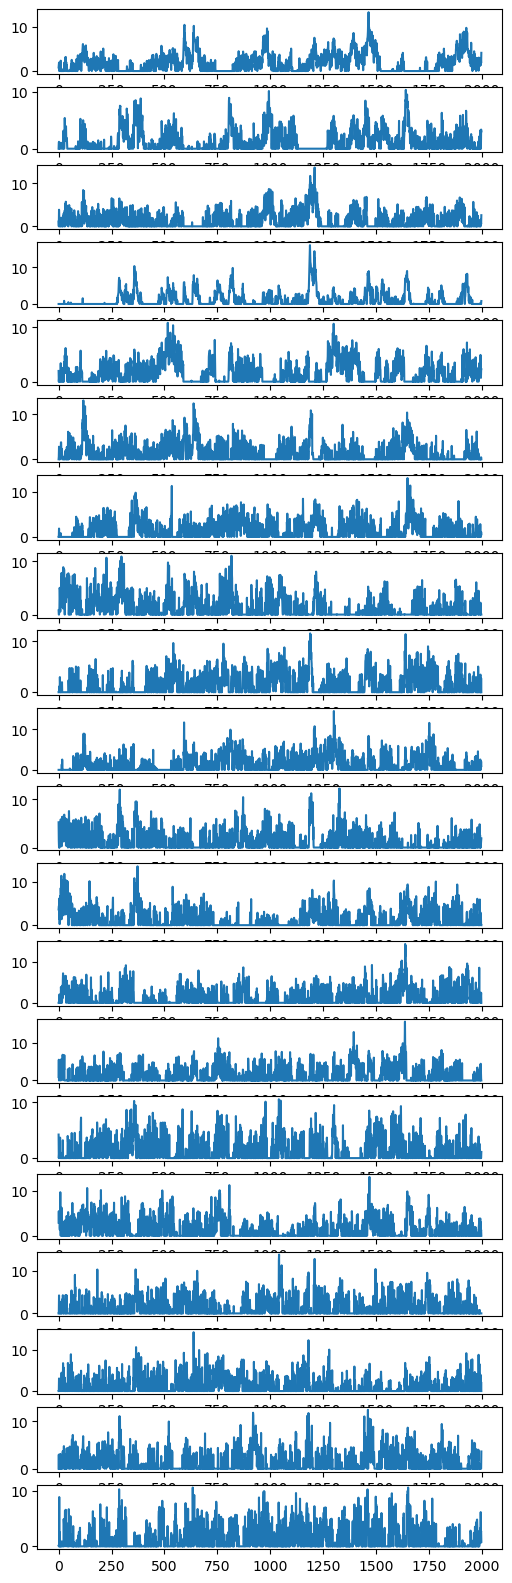

In [30]:
fig, ax = plt.subplots(k, 1, figsize=(1 * 6, k * 1))
for col in range(0,k):
    ax[col].plot(Y[col,:])
plt.show()

Wp.shape = (20, 1200)
k = 20


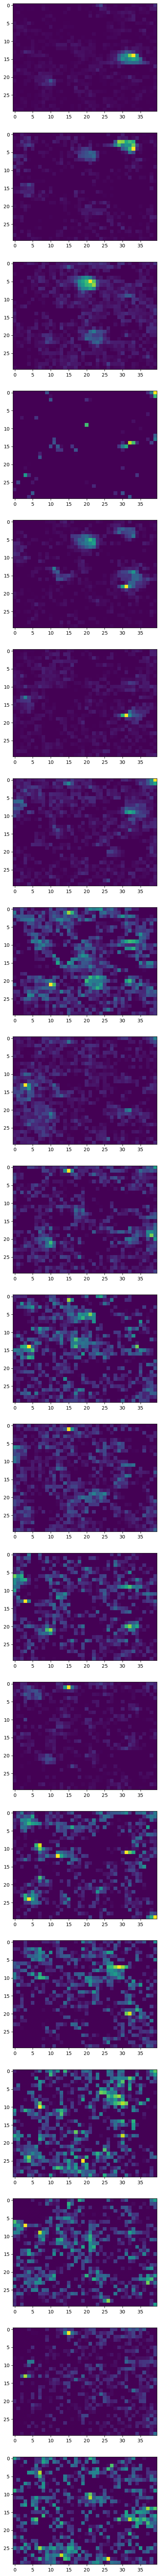

In [32]:
print (f"Wp.shape = {Wp.shape}")
print (f"k = {k}")

image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(Wf[entry,:])
    image_array += [snapshot]

fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
for row in range(0,k):
    ax[row].imshow(image_array[row])
plt.show()